In [1]:
%pip install mapof.marriages

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [3]:
import mapof.marriages as mapof
import pandas
import ast
from ast import literal_eval
import numpy as np
from printing import print_map_2d_colored_by_feature
import json

In [18]:
reverse_euclid = pandas.read_csv('4_reverse_euclidean_with_rank_diff.csv')
mallows = pandas.read_csv('4_mallows_with_rank_diff.csv')
mallows_MD = pandas.read_csv('4_mallows_MD_with_rank_diff.csv')
mallows_MA = pandas.read_csv('4_mallows_MA_with_rank_diff.csv')
mallows_euclidean = pandas.read_csv('4_euclidean_mallows_with_rank_diff.csv')
expectations_euclidean = pandas.read_csv('4_expectations_euclidean_with_rank_diff.csv')
netflix = pandas.read_csv('netflix_preferences_with_rank_diff.csv')

In [19]:
reverse_euclid['preferences'] = reverse_euclid.apply(
    lambda row: [ast.literal_eval(row['mpref']), ast.literal_eval(row['wpref'])], axis=1
)
mallows['preferences'] = mallows.apply(
    lambda row: [ast.literal_eval(row['mpref']), ast.literal_eval(row['wpref'])], axis=1
)
mallows_MD['preferences'] = mallows_MD.apply(
    lambda row: [ast.literal_eval(row['mpref']), ast.literal_eval(row['wpref'])], axis=1
)
mallows_MA['preferences'] = mallows_MA.apply(
    lambda row: [ast.literal_eval(row['mpref']), ast.literal_eval(row['wpref'])], axis=1
)
mallows_euclidean['preferences'] = mallows_euclidean.apply(
    lambda row: [ast.literal_eval(row['mpref']), ast.literal_eval(row['wpref'])], axis=1
)
expectations_euclidean['preferences'] = expectations_euclidean.apply(
    lambda row: [ast.literal_eval(row['mpref']), ast.literal_eval(row['wpref'])], axis=1
)
netflix["preferences"] = netflix.apply(
    lambda row: [ast.literal_eval(row['Mpref']), ast.literal_eval(row['Wpref'])], axis=1)

In [20]:
files = [reverse_euclid, mallows, mallows_MD, mallows_MA, mallows_euclidean, expectations_euclidean, netflix]
normalized_features = ['trunc_count', 'trunc_egal', 'num_self_manipulators', 'avg_self_benefit', 'avg_best_benefit_acc', 'number_acc_manipulators',
                       'avg_best_benefit_two','number_two_manipulators']
for file in files:
    for feature in normalized_features:
        if feature in file.columns:
            file[feature] = file[feature] / 4

In [21]:
future_votes_rev_euclidean = reverse_euclid['preferences']
rev_euclid_feature = [reverse_euclid['trunc_count'], reverse_euclid['trunc_egal'],
                      reverse_euclid['trunc_prevalence'], reverse_euclid['num_self_manipulators'], reverse_euclid['avg_self_benefit'], 
                      reverse_euclid['self_freq_instance'], reverse_euclid['avg_best_benefit_acc'], reverse_euclid['number_acc_manipulators'],
                      reverse_euclid['acc_freq_instance'], reverse_euclid['avg_best_benefit_two'], reverse_euclid['number_two_manipulators'],
                      reverse_euclid['two_freq_instance']]
future_votes_mallows = mallows['preferences']
mallows_feature = [mallows['trunc_count'], mallows['trunc_egal'],
                   mallows['trunc_prevalence'], mallows['num_self_manipulators'], mallows['avg_self_benefit'], 
                      mallows['self_freq_instance'], mallows['avg_best_benefit_acc'], mallows['number_acc_manipulators'],
                      mallows['acc_freq_instance'], mallows['avg_best_benefit_two'], mallows['number_two_manipulators'],
                      mallows['two_freq_instance']]
future_votes_mallows_MD = mallows_MD['preferences']
mallows_MD_feature = [mallows_MD['trunc_count'], mallows_MD['trunc_egal'],
                        mallows_MD['trunc_prevalence'], mallows_MD['num_self_manipulators'], mallows_MD['avg_self_benefit'], 
                      mallows_MD['self_freq_instance'], mallows_MD['avg_best_benefit_acc'], mallows_MD['number_acc_manipulators'],
                      mallows_MD['acc_freq_instance'], mallows_MD['avg_best_benefit_two'], mallows_MD['number_two_manipulators'],
                      mallows_MD['two_freq_instance']]
future_votes_mallows_MA = mallows_MA['preferences']
mallows_MA_feature = [mallows_MA['trunc_count'], mallows_MA['trunc_egal'],
                       mallows_MA['trunc_prevalence'], mallows_MA['num_self_manipulators'], mallows_MA['avg_self_benefit'], 
                      mallows_MA['self_freq_instance'], mallows_MA['avg_best_benefit_acc'], mallows_MA['number_acc_manipulators'],
                      mallows_MA['acc_freq_instance'], mallows_MA['avg_best_benefit_two'], mallows_MA['number_two_manipulators'],
                      mallows_MA['two_freq_instance']]
future_votes_mallows_euclidean = mallows_euclidean['preferences']
mallows_euclidean_feature = [mallows_euclidean['trunc_count'], mallows_euclidean['trunc_egal'],
                              mallows_euclidean['trunc_prevalence'], mallows_euclidean['num_self_manipulators'], mallows_euclidean['avg_self_benefit'], 
                      mallows_euclidean['self_freq_instance'], mallows_euclidean['avg_best_benefit_acc'], mallows_euclidean['number_acc_manipulators'],
                      mallows_euclidean['acc_freq_instance'], mallows_euclidean['avg_best_benefit_two'], mallows_euclidean['number_two_manipulators'],
                      mallows_euclidean['two_freq_instance']]
future_votes_expectations_euclidean = expectations_euclidean['preferences']
expectations_euclidean_feature = [expectations_euclidean['trunc_count'], expectations_euclidean['trunc_egal'],
                                   expectations_euclidean['trunc_prevalence'], expectations_euclidean['num_self_manipulators'], expectations_euclidean['avg_self_benefit'], 
                      expectations_euclidean['self_freq_instance'], expectations_euclidean['avg_best_benefit_acc'], expectations_euclidean['number_acc_manipulators'],
                      expectations_euclidean['acc_freq_instance'], expectations_euclidean['avg_best_benefit_two'], expectations_euclidean['number_two_manipulators'],
                      expectations_euclidean['two_freq_instance']]
future_votes_netflix = netflix['preferences']
netflix_feature = [netflix['trunc_count'], netflix['trunc_egal'], netflix['trunc_prevalence'],
                    netflix['num_self_manipulators'], netflix['avg_self_benefit'], 
                      netflix['self_freq_instance'], netflix['avg_best_benefit_acc'], netflix['number_acc_manipulators'],
                      netflix['acc_freq_instance'], netflix['avg_best_benefit_two'], netflix['number_two_manipulators'],
                      netflix['two_freq_instance']]

In [22]:
for i in range(len(future_votes_rev_euclidean)):
        future_votes_rev_euclidean[i][0] = np.array(future_votes_rev_euclidean[i][0]) -1
        future_votes_rev_euclidean[i][1] =  np.array(future_votes_rev_euclidean[i][1]) -1
for i in range(len(future_votes_mallows)):
        future_votes_mallows[i][0] = np.array(future_votes_mallows[i][0]) -1
        future_votes_mallows[i][1] =  np.array(future_votes_mallows[i][1]) -1

for i in range(len(future_votes_mallows_MD)):
        future_votes_mallows_MD[i][0] = np.array(future_votes_mallows_MD[i][0]) -1
        future_votes_mallows_MD[i][1] =  np.array(future_votes_mallows_MD[i][1]) -1

for i in range(len(future_votes_mallows_MA)):
        future_votes_mallows_MA[i][0] = np.array(future_votes_mallows_MA[i][0]) -1
        future_votes_mallows_MA[i][1] =  np.array(future_votes_mallows_MA[i][1]) -1

for i in range(len(future_votes_mallows_euclidean)):
        future_votes_mallows_euclidean[i][0] = np.array(future_votes_mallows_euclidean[i][0]) -1
        future_votes_mallows_euclidean[i][1] =  np.array(future_votes_mallows_euclidean[i][1]) -1

for i in range(len(future_votes_expectations_euclidean)):
        future_votes_expectations_euclidean[i][0] = np.array(future_votes_expectations_euclidean[i][0]) -1
        future_votes_expectations_euclidean[i][1] =  np.array(future_votes_expectations_euclidean[i][1]) -1

for i in range(len(future_votes_netflix)):
        future_votes_netflix[i][0] = np.array(future_votes_netflix[i][0]) -1
        future_votes_netflix[i][1] =  np.array(future_votes_netflix[i][1]) -1

In [23]:
import mapof.core.objects.Experiment as E
from printing import print_map_2d_colored_by_feature

def patched(self, **kwargs):
    return print_map_2d_colored_by_feature(self, **kwargs)

E.Experiment.print_map_2d_colored_by_feature = patched

**General Map**

In [24]:
general = mapof.prepare_online_marriages_experiment()

In [25]:
general.add_family(culture_id = 'reverse_euclidean', size = 150, label = 'Semi-Euclidean', color = 'red', num_agents=4)

general.add_family(culture_id = 'norm-mallows', size = 150, label="Mallows-Identical", color = 'blue', num_agents=4)

general.add_family(culture_id = 'asymmetric', size = 150, label = 'Mallows-MD', color = 'green', num_agents=4)

general.add_family(culture_id = 'symmetric', size = 150, label = 'Mallows-MA', color = 'orange', num_agents=4)

general.add_family(culture_id = 'mallows_euclidean', size = 150, label = 'Mallows-Euclidean', color = 'purple', num_agents=4)

general.add_family(culture_id = 'expectation', size = 150, label = 'Expectation-Euclidean', color = 'brown', num_agents=4)

general.add_family(size = 150, label = 'Netflix', color = 'pink', num_agents=4)

['none_4_0',
 'none_4_1',
 'none_4_2',
 'none_4_3',
 'none_4_4',
 'none_4_5',
 'none_4_6',
 'none_4_7',
 'none_4_8',
 'none_4_9',
 'none_4_10',
 'none_4_11',
 'none_4_12',
 'none_4_13',
 'none_4_14',
 'none_4_15',
 'none_4_16',
 'none_4_17',
 'none_4_18',
 'none_4_19',
 'none_4_20',
 'none_4_21',
 'none_4_22',
 'none_4_23',
 'none_4_24',
 'none_4_25',
 'none_4_26',
 'none_4_27',
 'none_4_28',
 'none_4_29',
 'none_4_30',
 'none_4_31',
 'none_4_32',
 'none_4_33',
 'none_4_34',
 'none_4_35',
 'none_4_36',
 'none_4_37',
 'none_4_38',
 'none_4_39',
 'none_4_40',
 'none_4_41',
 'none_4_42',
 'none_4_43',
 'none_4_44',
 'none_4_45',
 'none_4_46',
 'none_4_47',
 'none_4_48',
 'none_4_49',
 'none_4_50',
 'none_4_51',
 'none_4_52',
 'none_4_53',
 'none_4_54',
 'none_4_55',
 'none_4_56',
 'none_4_57',
 'none_4_58',
 'none_4_59',
 'none_4_60',
 'none_4_61',
 'none_4_62',
 'none_4_63',
 'none_4_64',
 'none_4_65',
 'none_4_66',
 'none_4_67',
 'none_4_68',
 'none_4_69',
 'none_4_70',
 'none_4_71',
 '

In [26]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0
netflix_counter = 0

for key in general.instances.keys():
    if key.startswith('reverse_euclidean'):
        general.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        #experiment4.instances[key].features['self_freq_instance'] = rev_euclid_feature[reverse_euc_counter]
        reverse_euc_counter += 10
    elif key.startswith('norm-mallows_'):
        general.instances[key].votes = future_votes_mallows[mallows_counter]
        #experiment4.instances[key].features['self_freq_instance'] = mallows_feature[mallows_counter]
        mallows_counter += 12
    elif key.startswith('asymmetric_'):
        general.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        #experiment4.instances[key].features['self_freq_instance'] = mallows_MD_feature[mallows_MD_counter]
        mallows_MD_counter += 12
    elif key.startswith('symmetric_'):
        general.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        #experiment4.instances[key].features['self_freq_instance'] = mallows_MA_feature[mallows_MA_counter]
        mallows_MA_counter += 12
    elif key.startswith('mallows_euclidean_'):
        general.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        #experiment4.instances[key].features['self_freq_instance'] = mallows_euclidean_feature[mallows_euclidean_counter]
        mallows_euclidean_counter += 12
    elif key.startswith('expectation_'):
        general.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        #experiment4.instances[key].features['self_freq_instance'] = expectations_euclidean_feature[expectations_euclidean_counter]
        expectations_euclidean_counter += 10
    elif key.startswith('none_'):
        general.instances[key].votes = future_votes_netflix[netflix_counter]
        #experiment4.instances[key].features['self_freq_instance'] = expectations_euclidean_feature[expectations_euclidean_counter]
        netflix_counter += 1


In [27]:
general.compute_distances(distance_id='l1-mutual_attraction')
general.embed_2d(embedding_id='kk')

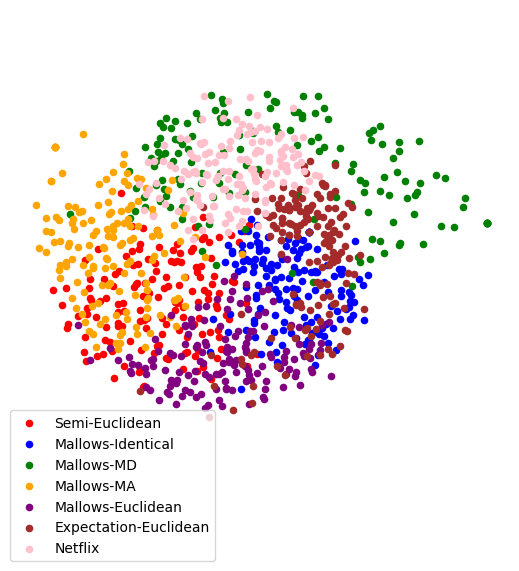

In [42]:
general.print_map_2d(saveas='4_general_map.pdf',legend_pos = (0.2, 0.2), angle = 3.14159)

**Truncation Prevalence**

In [43]:
trunc_prevalence = mapof.prepare_online_marriages_experiment()

In [44]:
trunc_prevalence.add_family(culture_id = 'reverse_euclidean', size = 150, label = 'Semi-Euclidean', num_agents=4)

trunc_prevalence.add_family(culture_id = 'norm-mallows', size = 150, label="Mallows-Identical", num_agents=4)

trunc_prevalence.add_family(culture_id = 'asymmetric', size = 150, label = 'Mallows-MD', num_agents=4)

trunc_prevalence.add_family(culture_id = 'symmetric', size = 150, label = 'Mallows-MA', num_agents=4)

trunc_prevalence.add_family(culture_id = 'mallows_euclidean', size = 150, label = 'Mallows-Euclidean', num_agents=4)

trunc_prevalence.add_family(culture_id = 'expectation', size = 150, label = 'Expectation-Euclidean', num_agents=4)

trunc_prevalence.add_family(size = 150, label = 'Netflix', num_agents=4)

['none_4_0',
 'none_4_1',
 'none_4_2',
 'none_4_3',
 'none_4_4',
 'none_4_5',
 'none_4_6',
 'none_4_7',
 'none_4_8',
 'none_4_9',
 'none_4_10',
 'none_4_11',
 'none_4_12',
 'none_4_13',
 'none_4_14',
 'none_4_15',
 'none_4_16',
 'none_4_17',
 'none_4_18',
 'none_4_19',
 'none_4_20',
 'none_4_21',
 'none_4_22',
 'none_4_23',
 'none_4_24',
 'none_4_25',
 'none_4_26',
 'none_4_27',
 'none_4_28',
 'none_4_29',
 'none_4_30',
 'none_4_31',
 'none_4_32',
 'none_4_33',
 'none_4_34',
 'none_4_35',
 'none_4_36',
 'none_4_37',
 'none_4_38',
 'none_4_39',
 'none_4_40',
 'none_4_41',
 'none_4_42',
 'none_4_43',
 'none_4_44',
 'none_4_45',
 'none_4_46',
 'none_4_47',
 'none_4_48',
 'none_4_49',
 'none_4_50',
 'none_4_51',
 'none_4_52',
 'none_4_53',
 'none_4_54',
 'none_4_55',
 'none_4_56',
 'none_4_57',
 'none_4_58',
 'none_4_59',
 'none_4_60',
 'none_4_61',
 'none_4_62',
 'none_4_63',
 'none_4_64',
 'none_4_65',
 'none_4_66',
 'none_4_67',
 'none_4_68',
 'none_4_69',
 'none_4_70',
 'none_4_71',
 '

In [45]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0
netflix_counter = 0

for key in trunc_prevalence.instances.keys():
    if key.startswith('reverse_euclidean'):
        trunc_prevalence.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        trunc_prevalence.instances[key].features['trunc_prevalence'] = rev_euclid_feature[2][reverse_euc_counter]
        reverse_euc_counter += 10
    elif key.startswith('norm-mallows_'):
        trunc_prevalence.instances[key].votes = future_votes_mallows[mallows_counter]
        trunc_prevalence.instances[key].features['trunc_prevalence'] = mallows_feature[2][mallows_counter]
        mallows_counter += 12
    elif key.startswith('asymmetric_'):
        trunc_prevalence.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        trunc_prevalence.instances[key].features['trunc_prevalence'] = mallows_MD_feature[2][mallows_MD_counter]
        mallows_MD_counter += 12
    elif key.startswith('symmetric_'):
        trunc_prevalence.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        trunc_prevalence.instances[key].features['trunc_prevalence'] = mallows_MA_feature[2][mallows_MA_counter]
        mallows_MA_counter += 12
    elif key.startswith('mallows_euclidean_'):
        trunc_prevalence.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        trunc_prevalence.instances[key].features['trunc_prevalence'] = mallows_euclidean_feature[2][mallows_euclidean_counter]
        mallows_euclidean_counter += 12
    elif key.startswith('expectation_'):
        trunc_prevalence.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        trunc_prevalence.instances[key].features['trunc_prevalence'] = expectations_euclidean_feature[2][expectations_euclidean_counter]
        expectations_euclidean_counter += 10
    elif key.startswith('none_'):
        trunc_prevalence.instances[key].votes = future_votes_netflix[netflix_counter]
        trunc_prevalence.instances[key].features['trunc_prevalence'] = netflix_feature[2][netflix_counter]
        netflix_counter += 1


In [46]:
trunc_prevalence.features['trunc_prevalence'] = {'value':{}}
for key in trunc_prevalence.instances.keys():
    trunc_prevalence.features['trunc_prevalence']['value'][key] = (trunc_prevalence.instances[key].features['trunc_prevalence'])

trunc_prevalence.experiment_id = 'trunc_prevalence'

In [47]:
trunc_prevalence.compute_distances(distance_id='l1-mutual_attraction')
trunc_prevalence.embed_2d(embedding_id='kk')

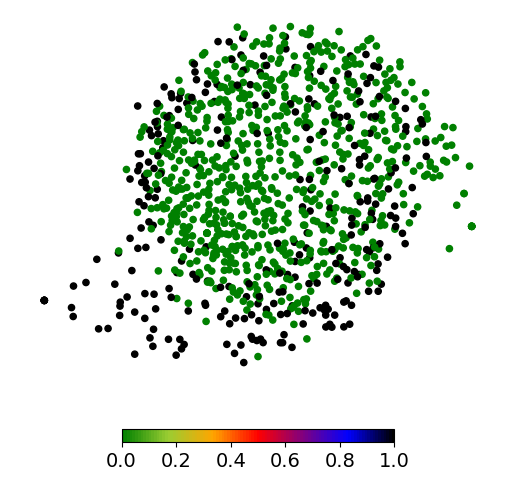

In [48]:
trunc_prevalence.print_map_2d_colored_by_feature(saveas='4_trunc_prevalence_map.pdf', feature_id = 'trunc_prevalence')

**Truncation Count**

In [49]:
trunc_count = mapof.prepare_online_marriages_experiment()

In [50]:
trunc_count.add_family(culture_id = 'reverse_euclidean', size = 150, label = 'Semi-Euclidean', num_agents=4)

trunc_count.add_family(culture_id = 'norm-mallows', size = 150, label="Mallows-Identical", num_agents=4)

trunc_count.add_family(culture_id = 'asymmetric', size = 150, label = 'Mallows-MD', num_agents=4)

trunc_count.add_family(culture_id = 'symmetric', size = 150, label = 'Mallows-MA', num_agents=4)

trunc_count.add_family(culture_id = 'mallows_euclidean', size = 150, label = 'Mallows-Euclidean', num_agents=4)

trunc_count.add_family(culture_id = 'expectation', size = 150, label = 'Expectation-Euclidean', num_agents=4)

trunc_count.add_family(size = 150, label = 'Netflix', num_agents=4)

['none_4_0',
 'none_4_1',
 'none_4_2',
 'none_4_3',
 'none_4_4',
 'none_4_5',
 'none_4_6',
 'none_4_7',
 'none_4_8',
 'none_4_9',
 'none_4_10',
 'none_4_11',
 'none_4_12',
 'none_4_13',
 'none_4_14',
 'none_4_15',
 'none_4_16',
 'none_4_17',
 'none_4_18',
 'none_4_19',
 'none_4_20',
 'none_4_21',
 'none_4_22',
 'none_4_23',
 'none_4_24',
 'none_4_25',
 'none_4_26',
 'none_4_27',
 'none_4_28',
 'none_4_29',
 'none_4_30',
 'none_4_31',
 'none_4_32',
 'none_4_33',
 'none_4_34',
 'none_4_35',
 'none_4_36',
 'none_4_37',
 'none_4_38',
 'none_4_39',
 'none_4_40',
 'none_4_41',
 'none_4_42',
 'none_4_43',
 'none_4_44',
 'none_4_45',
 'none_4_46',
 'none_4_47',
 'none_4_48',
 'none_4_49',
 'none_4_50',
 'none_4_51',
 'none_4_52',
 'none_4_53',
 'none_4_54',
 'none_4_55',
 'none_4_56',
 'none_4_57',
 'none_4_58',
 'none_4_59',
 'none_4_60',
 'none_4_61',
 'none_4_62',
 'none_4_63',
 'none_4_64',
 'none_4_65',
 'none_4_66',
 'none_4_67',
 'none_4_68',
 'none_4_69',
 'none_4_70',
 'none_4_71',
 '

In [51]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0
netflix_counter = 0

for key in trunc_count.instances.keys():
    if key.startswith('reverse_euclidean'):
        trunc_count.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        trunc_count.instances[key].features['trunc_count'] = rev_euclid_feature[0][reverse_euc_counter]
        reverse_euc_counter += 10
    elif key.startswith('norm-mallows_'):
        trunc_count.instances[key].votes = future_votes_mallows[mallows_counter]
        trunc_count.instances[key].features['trunc_count'] = mallows_feature[0][mallows_counter]
        mallows_counter += 12
    elif key.startswith('asymmetric_'):
        trunc_count.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        trunc_count.instances[key].features['trunc_count'] = mallows_MD_feature[0][mallows_MD_counter]
        mallows_MD_counter += 12
    elif key.startswith('symmetric_'):
        trunc_count.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        trunc_count.instances[key].features['trunc_count'] = mallows_MA_feature[0][mallows_MA_counter]
        mallows_MA_counter += 12
    elif key.startswith('mallows_euclidean_'):
        trunc_count.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        trunc_count.instances[key].features['trunc_count'] = mallows_euclidean_feature[0][mallows_euclidean_counter]
        mallows_euclidean_counter += 12
    elif key.startswith('expectation_'):
        trunc_count.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        trunc_count.instances[key].features['trunc_count'] = expectations_euclidean_feature[0][expectations_euclidean_counter]
        expectations_euclidean_counter += 10
    elif key.startswith('none_'):
        trunc_count.instances[key].votes = future_votes_netflix[netflix_counter]
        trunc_count.instances[key].features['trunc_count'] = netflix_feature[0][netflix_counter]
        netflix_counter += 1


In [52]:
trunc_count.features['trunc_count'] = {'value':{}}
for key in trunc_count.instances.keys():
    trunc_count.features['trunc_count']['value'][key] = (trunc_count.instances[key].features['trunc_count'])

trunc_count.experiment_id = 'trunc_count'

In [53]:
trunc_count.compute_distances(distance_id='l1-mutual_attraction')
trunc_count.embed_2d(embedding_id='kk')

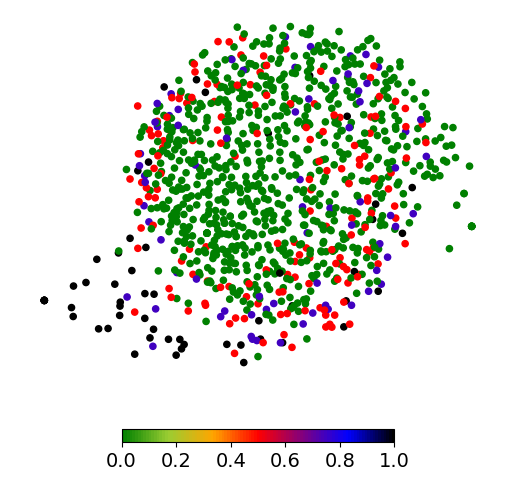

In [54]:
trunc_count.print_map_2d_colored_by_feature(saveas='4_trunc_count_map.pdf', feature_id = 'trunc_count')

**Trunc Egal**

In [63]:
trunc_egal = mapof.prepare_online_marriages_experiment()

In [64]:
trunc_egal.add_family(culture_id = 'reverse_euclidean', size = 150, label = 'Semi-Euclidean', num_agents=4)

trunc_egal.add_family(culture_id = 'norm-mallows', size = 150, label="Mallows-Identical", num_agents=4)

trunc_egal.add_family(culture_id = 'asymmetric', size = 150, label = 'Mallows-MD', num_agents=4)

trunc_egal.add_family(culture_id = 'symmetric', size = 150, label = 'Mallows-MA', num_agents=4)

trunc_egal.add_family(culture_id = 'mallows_euclidean', size = 150, label = 'Mallows-Euclidean', num_agents=4)

trunc_egal.add_family(culture_id = 'expectation', size = 150, label = 'Expectation-Euclidean', num_agents=4)

trunc_egal.add_family(size = 150, label = 'Netflix', num_agents=4)

['none_4_0',
 'none_4_1',
 'none_4_2',
 'none_4_3',
 'none_4_4',
 'none_4_5',
 'none_4_6',
 'none_4_7',
 'none_4_8',
 'none_4_9',
 'none_4_10',
 'none_4_11',
 'none_4_12',
 'none_4_13',
 'none_4_14',
 'none_4_15',
 'none_4_16',
 'none_4_17',
 'none_4_18',
 'none_4_19',
 'none_4_20',
 'none_4_21',
 'none_4_22',
 'none_4_23',
 'none_4_24',
 'none_4_25',
 'none_4_26',
 'none_4_27',
 'none_4_28',
 'none_4_29',
 'none_4_30',
 'none_4_31',
 'none_4_32',
 'none_4_33',
 'none_4_34',
 'none_4_35',
 'none_4_36',
 'none_4_37',
 'none_4_38',
 'none_4_39',
 'none_4_40',
 'none_4_41',
 'none_4_42',
 'none_4_43',
 'none_4_44',
 'none_4_45',
 'none_4_46',
 'none_4_47',
 'none_4_48',
 'none_4_49',
 'none_4_50',
 'none_4_51',
 'none_4_52',
 'none_4_53',
 'none_4_54',
 'none_4_55',
 'none_4_56',
 'none_4_57',
 'none_4_58',
 'none_4_59',
 'none_4_60',
 'none_4_61',
 'none_4_62',
 'none_4_63',
 'none_4_64',
 'none_4_65',
 'none_4_66',
 'none_4_67',
 'none_4_68',
 'none_4_69',
 'none_4_70',
 'none_4_71',
 '

In [65]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0
netflix_counter = 0

for key in trunc_egal.instances.keys():
    if key.startswith('reverse_euclidean'):
        trunc_egal.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        trunc_egal.instances[key].features['trunc_egal'] = rev_euclid_feature[1][reverse_euc_counter]
        reverse_euc_counter += 10
    elif key.startswith('norm-mallows_'):
        trunc_egal.instances[key].votes = future_votes_mallows[mallows_counter]
        trunc_egal.instances[key].features['trunc_egal'] = mallows_feature[1][mallows_counter]
        mallows_counter += 12
    elif key.startswith('asymmetric_'):
        trunc_egal.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        trunc_egal.instances[key].features['trunc_egal'] = mallows_MD_feature[1][mallows_MD_counter]
        mallows_MD_counter += 12
    elif key.startswith('symmetric_'):
        trunc_egal.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        trunc_egal.instances[key].features['trunc_egal'] = mallows_MA_feature[1][mallows_MA_counter]
        mallows_MA_counter += 12
    elif key.startswith('mallows_euclidean_'):
        trunc_egal.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        trunc_egal.instances[key].features['trunc_egal'] = mallows_euclidean_feature[1][mallows_euclidean_counter]
        mallows_euclidean_counter += 12
    elif key.startswith('expectation_'):
        trunc_egal.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        trunc_egal.instances[key].features['trunc_egal'] = expectations_euclidean_feature[1][expectations_euclidean_counter]
        expectations_euclidean_counter += 10
    elif key.startswith('none_'):
        trunc_egal.instances[key].votes = future_votes_netflix[netflix_counter]
        trunc_egal.instances[key].features['trunc_egal'] = netflix_feature[1][netflix_counter]
        netflix_counter += 1


In [58]:
trunc_egal.features['trunc_egal'] = {'value':{}}
for key in trunc_egal.instances.keys():
    trunc_egal.features['trunc_egal']['value'][key] = (trunc_egal.instances[key].features['trunc_egal'])

trunc_egal.experiment_id = 'trunc_egal'

In [59]:
trunc_egal.compute_distances(distance_id='l1-mutual_attraction')
trunc_egal.embed_2d(embedding_id='kk')

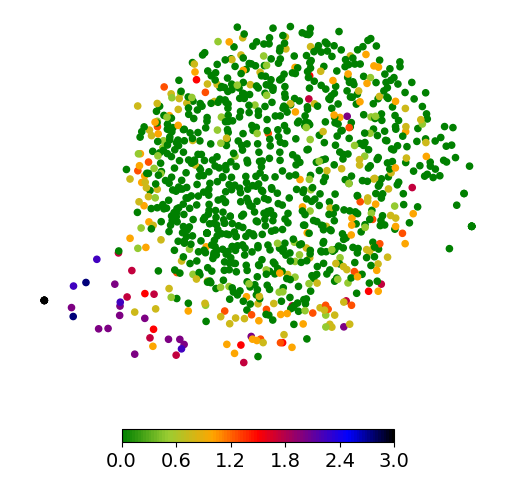

In [60]:
trunc_egal.print_map_2d_colored_by_feature(saveas='4_trunc_egal_map.pdf', feature_id = 'trunc_egal')

**Self Frequency**

In [66]:
self_freq = mapof.prepare_online_marriages_experiment()

In [67]:
self_freq.add_family(culture_id = 'reverse_euclidean', size = 150, label = 'Semi-Euclidean', num_agents=4)

self_freq.add_family(culture_id = 'norm-mallows', size = 150, label="Mallows-Identical", num_agents=4)

self_freq.add_family(culture_id = 'asymmetric', size = 150, label = 'Mallows-MD', num_agents=4)

self_freq.add_family(culture_id = 'symmetric', size = 150, label = 'Mallows-MA', num_agents=4)

self_freq.add_family(culture_id = 'mallows_euclidean', size = 150, label = 'Mallows-Euclidean', num_agents=4)

self_freq.add_family(culture_id = 'expectation', size = 150, label = 'Expectation-Euclidean', num_agents=4)

self_freq.add_family(size = 150, label = 'Netflix', num_agents=4)

['none_4_0',
 'none_4_1',
 'none_4_2',
 'none_4_3',
 'none_4_4',
 'none_4_5',
 'none_4_6',
 'none_4_7',
 'none_4_8',
 'none_4_9',
 'none_4_10',
 'none_4_11',
 'none_4_12',
 'none_4_13',
 'none_4_14',
 'none_4_15',
 'none_4_16',
 'none_4_17',
 'none_4_18',
 'none_4_19',
 'none_4_20',
 'none_4_21',
 'none_4_22',
 'none_4_23',
 'none_4_24',
 'none_4_25',
 'none_4_26',
 'none_4_27',
 'none_4_28',
 'none_4_29',
 'none_4_30',
 'none_4_31',
 'none_4_32',
 'none_4_33',
 'none_4_34',
 'none_4_35',
 'none_4_36',
 'none_4_37',
 'none_4_38',
 'none_4_39',
 'none_4_40',
 'none_4_41',
 'none_4_42',
 'none_4_43',
 'none_4_44',
 'none_4_45',
 'none_4_46',
 'none_4_47',
 'none_4_48',
 'none_4_49',
 'none_4_50',
 'none_4_51',
 'none_4_52',
 'none_4_53',
 'none_4_54',
 'none_4_55',
 'none_4_56',
 'none_4_57',
 'none_4_58',
 'none_4_59',
 'none_4_60',
 'none_4_61',
 'none_4_62',
 'none_4_63',
 'none_4_64',
 'none_4_65',
 'none_4_66',
 'none_4_67',
 'none_4_68',
 'none_4_69',
 'none_4_70',
 'none_4_71',
 '

In [70]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0
netflix_counter = 0

for key in self_freq.instances.keys():
    if key.startswith('reverse_euclidean'):
        self_freq.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        self_freq.instances[key].features['self_freq_instance'] = rev_euclid_feature[5][reverse_euc_counter]
        reverse_euc_counter += 10
    elif key.startswith('norm-mallows_'):
        self_freq.instances[key].votes = future_votes_mallows[mallows_counter]
        self_freq.instances[key].features['self_freq_instance'] = mallows_feature[5][mallows_counter]
        mallows_counter += 12
    elif key.startswith('asymmetric_'):
        self_freq.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        self_freq.instances[key].features['self_freq_instance'] = mallows_MD_feature[5][mallows_MD_counter]
        mallows_MD_counter += 12
    elif key.startswith('symmetric_'):
        self_freq.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        self_freq.instances[key].features['self_freq_instance'] = mallows_MA_feature[5][mallows_MA_counter]
        mallows_MA_counter += 12
    elif key.startswith('mallows_euclidean_'):
        self_freq.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        self_freq.instances[key].features['self_freq_instance'] = mallows_euclidean_feature[5][mallows_euclidean_counter]
        mallows_euclidean_counter += 12
    elif key.startswith('expectation_'):
        self_freq.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        self_freq.instances[key].features['self_freq_instance'] = expectations_euclidean_feature[5][expectations_euclidean_counter]
        expectations_euclidean_counter += 10
    elif key.startswith('none_'):
        self_freq.instances[key].votes = future_votes_netflix[netflix_counter]
        self_freq.instances[key].features['self_freq_instance'] = netflix_feature[5][netflix_counter]
        netflix_counter += 1


In [71]:
self_freq.features['self_freq_instance'] = {'value':{}}
for key in self_freq.instances.keys():
    self_freq.features['self_freq_instance']['value'][key] = (self_freq.instances[key].features['self_freq_instance'])

self_freq.experiment_id = 'self_freq_instance'

In [72]:
self_freq.compute_distances(distance_id='l1-mutual_attraction')
self_freq.embed_2d(embedding_id='kk')

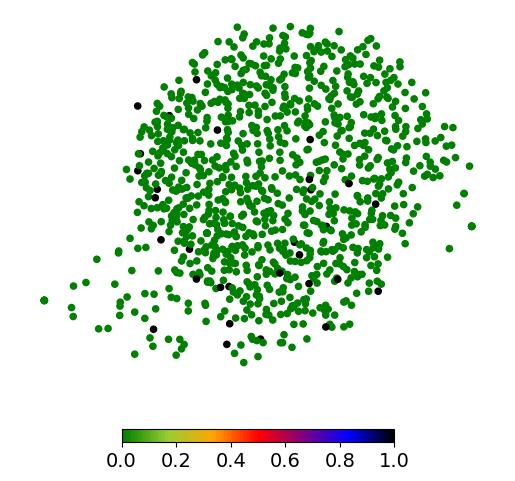

In [73]:
self_freq.print_map_2d_colored_by_feature(feature_id='self_freq_instance', saveas='4_self_freq_map.pdf')

**Self Manipulability**

In [74]:
self_manip = mapof.prepare_online_marriages_experiment()

In [75]:
self_manip.add_family(culture_id = 'reverse_euclidean', size = 150, label = 'Semi-Euclidean', num_agents=4)

self_manip.add_family(culture_id = 'norm-mallows', size = 150, label="Mallows-Identical", num_agents=4)

self_manip.add_family(culture_id = 'asymmetric', size = 150, label = 'Mallows-MD', num_agents=4)

self_manip.add_family(culture_id = 'symmetric', size = 150, label = 'Mallows-MA', num_agents=4)

self_manip.add_family(culture_id = 'mallows_euclidean', size = 150, label = 'Mallows-Euclidean', num_agents=4)

self_manip.add_family(culture_id = 'expectation', size = 150, label = 'Expectation-Euclidean', num_agents=4)

self_manip.add_family(size = 150, label = 'Netflix', num_agents=4)

['none_4_0',
 'none_4_1',
 'none_4_2',
 'none_4_3',
 'none_4_4',
 'none_4_5',
 'none_4_6',
 'none_4_7',
 'none_4_8',
 'none_4_9',
 'none_4_10',
 'none_4_11',
 'none_4_12',
 'none_4_13',
 'none_4_14',
 'none_4_15',
 'none_4_16',
 'none_4_17',
 'none_4_18',
 'none_4_19',
 'none_4_20',
 'none_4_21',
 'none_4_22',
 'none_4_23',
 'none_4_24',
 'none_4_25',
 'none_4_26',
 'none_4_27',
 'none_4_28',
 'none_4_29',
 'none_4_30',
 'none_4_31',
 'none_4_32',
 'none_4_33',
 'none_4_34',
 'none_4_35',
 'none_4_36',
 'none_4_37',
 'none_4_38',
 'none_4_39',
 'none_4_40',
 'none_4_41',
 'none_4_42',
 'none_4_43',
 'none_4_44',
 'none_4_45',
 'none_4_46',
 'none_4_47',
 'none_4_48',
 'none_4_49',
 'none_4_50',
 'none_4_51',
 'none_4_52',
 'none_4_53',
 'none_4_54',
 'none_4_55',
 'none_4_56',
 'none_4_57',
 'none_4_58',
 'none_4_59',
 'none_4_60',
 'none_4_61',
 'none_4_62',
 'none_4_63',
 'none_4_64',
 'none_4_65',
 'none_4_66',
 'none_4_67',
 'none_4_68',
 'none_4_69',
 'none_4_70',
 'none_4_71',
 '

In [76]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0
netflix_counter = 0

for key in self_manip.instances.keys():
    if key.startswith('reverse_euclidean'):
        self_manip.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        self_manip.instances[key].features['num_self_manipulators'] = rev_euclid_feature[3][reverse_euc_counter]
        reverse_euc_counter += 10
    elif key.startswith('norm-mallows_'):
        self_manip.instances[key].votes = future_votes_mallows[mallows_counter]
        self_manip.instances[key].features['num_self_manipulators'] = mallows_feature[3][mallows_counter]
        mallows_counter += 12
    elif key.startswith('asymmetric_'):
        self_manip.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        self_manip.instances[key].features['num_self_manipulators'] = mallows_MD_feature[3][mallows_MD_counter]
        mallows_MD_counter += 12
    elif key.startswith('symmetric_'):
        self_manip.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        self_manip.instances[key].features['num_self_manipulators'] = mallows_MA_feature[3][mallows_MA_counter]
        mallows_MA_counter += 12
    elif key.startswith('mallows_euclidean_'):
        self_manip.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        self_manip.instances[key].features['num_self_manipulators'] = mallows_euclidean_feature[3][mallows_euclidean_counter]
        mallows_euclidean_counter += 12
    elif key.startswith('expectation_'):
        self_manip.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        self_manip.instances[key].features['num_self_manipulators'] = expectations_euclidean_feature[3][expectations_euclidean_counter]
        expectations_euclidean_counter += 10
    elif key.startswith('none_'):
        self_manip.instances[key].votes = future_votes_netflix[netflix_counter]
        self_manip.instances[key].features['num_self_manipulators'] = netflix_feature[3][netflix_counter]
        netflix_counter += 1


In [77]:
self_manip.features['num_self_manipulators'] = {'value':{}}
for key in self_manip.instances.keys():
    self_manip.features['num_self_manipulators']['value'][key] = (self_manip.instances[key].features['num_self_manipulators'])

self_manip.experiment_id = 'self_manip_instance'

In [78]:
self_manip.compute_distances(distance_id='l1-mutual_attraction')
self_manip.embed_2d(embedding_id='kk')

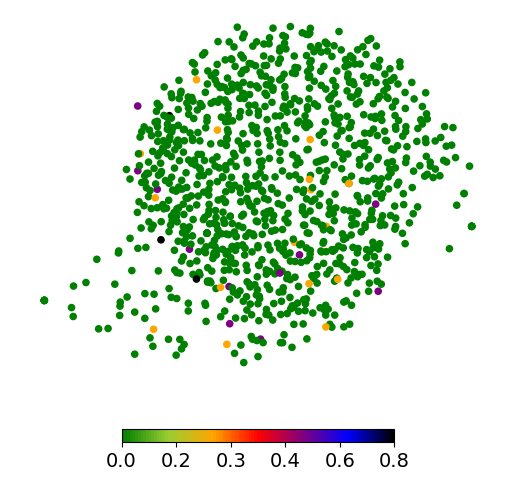

In [79]:
self_manip.print_map_2d_colored_by_feature(feature_id='num_self_manipulators', saveas='4_num_self_manipulators_map.pdf')

**Self Gain**

In [80]:
avg_self_benefit = mapof.prepare_online_marriages_experiment()

In [81]:
avg_self_benefit.add_family(culture_id = 'reverse_euclidean', size = 150, label = 'Semi-Euclidean', num_agents=4)

avg_self_benefit.add_family(culture_id = 'norm-mallows', size = 150, label="Mallows-Identical", num_agents=4)

avg_self_benefit.add_family(culture_id = 'asymmetric', size = 150, label = 'Mallows-MD', num_agents=4)

avg_self_benefit.add_family(culture_id = 'symmetric', size = 150, label = 'Mallows-MA', num_agents=4)

avg_self_benefit.add_family(culture_id = 'mallows_euclidean', size = 150, label = 'Mallows-Euclidean', num_agents=4)

avg_self_benefit.add_family(culture_id = 'expectation', size = 150, label = 'Expectation-Euclidean', num_agents=4)

avg_self_benefit.add_family(size = 150, label = 'Netflix', num_agents=4)

['none_4_0',
 'none_4_1',
 'none_4_2',
 'none_4_3',
 'none_4_4',
 'none_4_5',
 'none_4_6',
 'none_4_7',
 'none_4_8',
 'none_4_9',
 'none_4_10',
 'none_4_11',
 'none_4_12',
 'none_4_13',
 'none_4_14',
 'none_4_15',
 'none_4_16',
 'none_4_17',
 'none_4_18',
 'none_4_19',
 'none_4_20',
 'none_4_21',
 'none_4_22',
 'none_4_23',
 'none_4_24',
 'none_4_25',
 'none_4_26',
 'none_4_27',
 'none_4_28',
 'none_4_29',
 'none_4_30',
 'none_4_31',
 'none_4_32',
 'none_4_33',
 'none_4_34',
 'none_4_35',
 'none_4_36',
 'none_4_37',
 'none_4_38',
 'none_4_39',
 'none_4_40',
 'none_4_41',
 'none_4_42',
 'none_4_43',
 'none_4_44',
 'none_4_45',
 'none_4_46',
 'none_4_47',
 'none_4_48',
 'none_4_49',
 'none_4_50',
 'none_4_51',
 'none_4_52',
 'none_4_53',
 'none_4_54',
 'none_4_55',
 'none_4_56',
 'none_4_57',
 'none_4_58',
 'none_4_59',
 'none_4_60',
 'none_4_61',
 'none_4_62',
 'none_4_63',
 'none_4_64',
 'none_4_65',
 'none_4_66',
 'none_4_67',
 'none_4_68',
 'none_4_69',
 'none_4_70',
 'none_4_71',
 '

In [82]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0
netflix_counter = 0

for key in avg_self_benefit.instances.keys():
    if key.startswith('reverse_euclidean'):
        avg_self_benefit.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        avg_self_benefit.instances[key].features['avg_self_benefit'] = rev_euclid_feature[4][reverse_euc_counter]
        reverse_euc_counter += 10
    elif key.startswith('norm-mallows_'):
        avg_self_benefit.instances[key].votes = future_votes_mallows[mallows_counter]
        avg_self_benefit.instances[key].features['avg_self_benefit'] = mallows_feature[4][mallows_counter]
        mallows_counter += 12
    elif key.startswith('asymmetric_'):
        avg_self_benefit.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        avg_self_benefit.instances[key].features['avg_self_benefit'] = mallows_MD_feature[4][mallows_MD_counter]
        mallows_MD_counter += 12
    elif key.startswith('symmetric_'):
        avg_self_benefit.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        avg_self_benefit.instances[key].features['avg_self_benefit'] = mallows_MA_feature[4][mallows_MA_counter]
        mallows_MA_counter += 12
    elif key.startswith('mallows_euclidean_'):
        avg_self_benefit.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        avg_self_benefit.instances[key].features['avg_self_benefit'] = mallows_euclidean_feature[4][mallows_euclidean_counter]
        mallows_euclidean_counter += 12
    elif key.startswith('expectation_'):
        avg_self_benefit.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        avg_self_benefit.instances[key].features['avg_self_benefit'] = expectations_euclidean_feature[4][expectations_euclidean_counter]
        expectations_euclidean_counter += 10
    elif key.startswith('none_'):
        avg_self_benefit.instances[key].votes = future_votes_netflix[netflix_counter]
        avg_self_benefit.instances[key].features['avg_self_benefit'] = netflix_feature[4][netflix_counter]
        netflix_counter += 1


In [83]:
avg_self_benefit.features['avg_self_benefit'] = {'value':{}}
for key in avg_self_benefit.instances.keys():
    avg_self_benefit.features['avg_self_benefit']['value'][key] = (avg_self_benefit.instances[key].features['avg_self_benefit'])

avg_self_benefit.experiment_id = 'avg_self_benefit'

In [84]:
avg_self_benefit.compute_distances(distance_id='l1-mutual_attraction')
avg_self_benefit.embed_2d(embedding_id='kk')

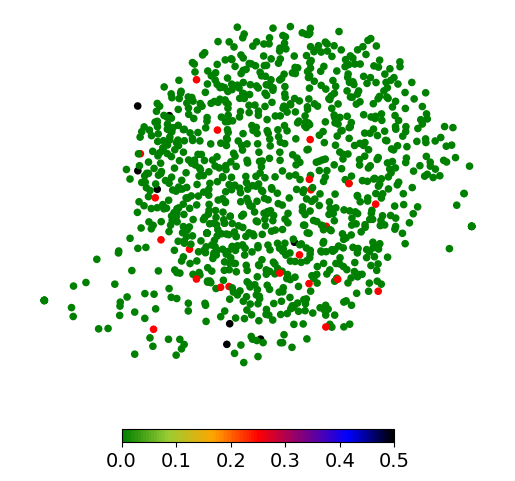

In [85]:
avg_self_benefit.print_map_2d_colored_by_feature(feature_id='avg_self_benefit', saveas='4_avg_self_benefit_map.pdf')

**Accomplice Gain**

In [86]:
gain_acc = mapof.prepare_online_marriages_experiment()

In [ ]:
gain_acc.add_family(culture_id = 'reverse_euclidean', size = 150, label = 'Semi-Euclidean', num_agents=4)

gain_acc.add_family(culture_id = 'norm-mallows', size = 150, label="Mallows-Identical", num_agents=4)

gain_acc.add_family(culture_id = 'asymmetric', size = 150, label = 'Mallows-MD', num_agents=4)

gain_acc.add_family(culture_id = 'symmetric', size = 150, label = 'Mallows-MA', num_agents=4)

gain_acc.add_family(culture_id = 'mallows_euclidean', size = 150, label = 'Mallows-Euclidean', num_agents=4)

gain_acc.add_family(culture_id = 'expectation', size = 150, label = 'Expectation-Euclidean', num_agents=4)

gain_acc.add_family(size = 150, label = 'Netflix', num_agents=4)

['none_4_0',
 'none_4_1',
 'none_4_2',
 'none_4_3',
 'none_4_4',
 'none_4_5',
 'none_4_6',
 'none_4_7',
 'none_4_8',
 'none_4_9',
 'none_4_10',
 'none_4_11',
 'none_4_12',
 'none_4_13',
 'none_4_14',
 'none_4_15',
 'none_4_16',
 'none_4_17',
 'none_4_18',
 'none_4_19',
 'none_4_20',
 'none_4_21',
 'none_4_22',
 'none_4_23',
 'none_4_24',
 'none_4_25',
 'none_4_26',
 'none_4_27',
 'none_4_28',
 'none_4_29',
 'none_4_30',
 'none_4_31',
 'none_4_32',
 'none_4_33',
 'none_4_34',
 'none_4_35',
 'none_4_36',
 'none_4_37',
 'none_4_38',
 'none_4_39',
 'none_4_40',
 'none_4_41',
 'none_4_42',
 'none_4_43',
 'none_4_44',
 'none_4_45',
 'none_4_46',
 'none_4_47',
 'none_4_48',
 'none_4_49',
 'none_4_50',
 'none_4_51',
 'none_4_52',
 'none_4_53',
 'none_4_54',
 'none_4_55',
 'none_4_56',
 'none_4_57',
 'none_4_58',
 'none_4_59',
 'none_4_60',
 'none_4_61',
 'none_4_62',
 'none_4_63',
 'none_4_64',
 'none_4_65',
 'none_4_66',
 'none_4_67',
 'none_4_68',
 'none_4_69',
 'none_4_70',
 'none_4_71',
 '

In [88]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0
netflix_counter = 0

for key in gain_acc.instances.keys():
    if key.startswith('reverse_euclidean'):
        gain_acc.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        gain_acc.instances[key].features['avg_best_benefit_acc'] = rev_euclid_feature[6][reverse_euc_counter]
        reverse_euc_counter += 10
    elif key.startswith('norm-mallows_'):
        gain_acc.instances[key].votes = future_votes_mallows[mallows_counter]
        gain_acc.instances[key].features['avg_best_benefit_acc'] = mallows_feature[6][mallows_counter]
        mallows_counter += 12
    elif key.startswith('asymmetric_'):
        gain_acc.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        gain_acc.instances[key].features['avg_best_benefit_acc'] = mallows_MD_feature[6][mallows_MD_counter]
        mallows_MD_counter += 12
    elif key.startswith('symmetric_'):
        gain_acc.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        gain_acc.instances[key].features['avg_best_benefit_acc'] = mallows_MA_feature[6][mallows_MA_counter]
        mallows_MA_counter += 12
    elif key.startswith('mallows_euclidean_'):
        gain_acc.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        gain_acc.instances[key].features['avg_best_benefit_acc'] = mallows_euclidean_feature[6][mallows_euclidean_counter]
        mallows_euclidean_counter += 12
    elif key.startswith('expectation_'):
        gain_acc.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        gain_acc.instances[key].features['avg_best_benefit_acc'] = expectations_euclidean_feature[6][expectations_euclidean_counter]
        expectations_euclidean_counter += 10
    elif key.startswith('none_'):
        gain_acc.instances[key].votes = future_votes_netflix[netflix_counter]
        gain_acc.instances[key].features['avg_best_benefit_acc'] = netflix_feature[6][netflix_counter]
        netflix_counter += 1


In [89]:
gain_acc.features['avg_best_benefit_acc'] = {'value':{}}
for key in gain_acc.instances.keys():
    gain_acc.features['avg_best_benefit_acc']['value'][key] = (gain_acc.instances[key].features['avg_best_benefit_acc'])

gain_acc.experiment_id = 'avg_best_benefit_acc'

In [90]:
gain_acc.compute_distances(distance_id='l1-mutual_attraction')
gain_acc.embed_2d(embedding_id='kk')

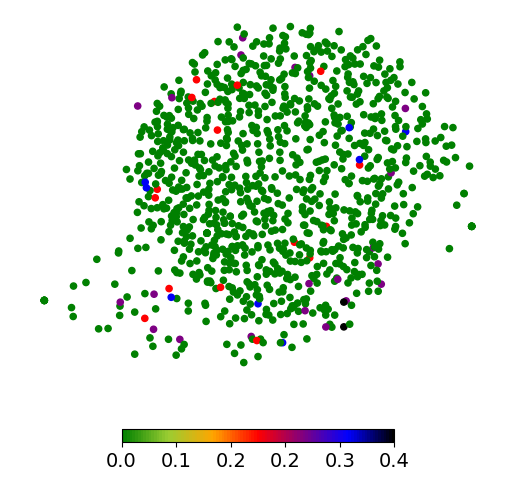

In [91]:
gain_acc.print_map_2d_colored_by_feature(feature_id='avg_best_benefit_acc', saveas='4_benefit_acc_map.pdf')

**Accomplice Manipulators**

In [92]:
acc_manip = mapof.prepare_online_marriages_experiment()

In [93]:
acc_manip.add_family(culture_id = 'reverse_euclidean', size = 150, label = 'Semi-Euclidean', num_agents=4)

acc_manip.add_family(culture_id = 'norm-mallows', size = 150, label="Mallows-Identical", num_agents=4)

acc_manip.add_family(culture_id = 'asymmetric', size = 150, label = 'Mallows-MD', num_agents=4)

acc_manip.add_family(culture_id = 'symmetric', size = 150, label = 'Mallows-MA', num_agents=4)

acc_manip.add_family(culture_id = 'mallows_euclidean', size = 150, label = 'Mallows-Euclidean', num_agents=4)

acc_manip.add_family(culture_id = 'expectation', size = 150, label = 'Expectation-Euclidean', num_agents=4)

acc_manip.add_family(size = 150, label = 'Netflix', num_agents=4)

['none_4_0',
 'none_4_1',
 'none_4_2',
 'none_4_3',
 'none_4_4',
 'none_4_5',
 'none_4_6',
 'none_4_7',
 'none_4_8',
 'none_4_9',
 'none_4_10',
 'none_4_11',
 'none_4_12',
 'none_4_13',
 'none_4_14',
 'none_4_15',
 'none_4_16',
 'none_4_17',
 'none_4_18',
 'none_4_19',
 'none_4_20',
 'none_4_21',
 'none_4_22',
 'none_4_23',
 'none_4_24',
 'none_4_25',
 'none_4_26',
 'none_4_27',
 'none_4_28',
 'none_4_29',
 'none_4_30',
 'none_4_31',
 'none_4_32',
 'none_4_33',
 'none_4_34',
 'none_4_35',
 'none_4_36',
 'none_4_37',
 'none_4_38',
 'none_4_39',
 'none_4_40',
 'none_4_41',
 'none_4_42',
 'none_4_43',
 'none_4_44',
 'none_4_45',
 'none_4_46',
 'none_4_47',
 'none_4_48',
 'none_4_49',
 'none_4_50',
 'none_4_51',
 'none_4_52',
 'none_4_53',
 'none_4_54',
 'none_4_55',
 'none_4_56',
 'none_4_57',
 'none_4_58',
 'none_4_59',
 'none_4_60',
 'none_4_61',
 'none_4_62',
 'none_4_63',
 'none_4_64',
 'none_4_65',
 'none_4_66',
 'none_4_67',
 'none_4_68',
 'none_4_69',
 'none_4_70',
 'none_4_71',
 '

In [94]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0
netflix_counter = 0

for key in acc_manip.instances.keys():
    if key.startswith('reverse_euclidean'):
        acc_manip.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        acc_manip.instances[key].features['number_acc_manipulators'] = rev_euclid_feature[7][reverse_euc_counter]
        reverse_euc_counter += 10
    elif key.startswith('norm-mallows_'):
        acc_manip.instances[key].votes = future_votes_mallows[mallows_counter]
        acc_manip.instances[key].features['number_acc_manipulators'] = mallows_feature[7][mallows_counter]
        mallows_counter += 12
    elif key.startswith('asymmetric_'):
        acc_manip.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        acc_manip.instances[key].features['number_acc_manipulators'] = mallows_MD_feature[7][mallows_MD_counter]
        mallows_MD_counter += 12
    elif key.startswith('symmetric_'):
        acc_manip.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        acc_manip.instances[key].features['number_acc_manipulators'] = mallows_MA_feature[7][mallows_MA_counter]
        mallows_MA_counter += 12
    elif key.startswith('mallows_euclidean_'):
        acc_manip.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        acc_manip.instances[key].features['number_acc_manipulators'] = mallows_euclidean_feature[7][mallows_euclidean_counter]
        mallows_euclidean_counter += 12
    elif key.startswith('expectation_'):
        acc_manip.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        acc_manip.instances[key].features['number_acc_manipulators'] = expectations_euclidean_feature[7][expectations_euclidean_counter]
        expectations_euclidean_counter += 10
    elif key.startswith('none_'):
        acc_manip.instances[key].votes = future_votes_netflix[netflix_counter]
        acc_manip.instances[key].features['number_acc_manipulators'] = netflix_feature[7][netflix_counter]
        netflix_counter += 1


In [95]:
acc_manip.features['number_acc_manipulators'] = {'value':{}}
for key in acc_manip.instances.keys():
    acc_manip.features['number_acc_manipulators']['value'][key] = (acc_manip.instances[key].features['number_acc_manipulators'])

acc_manip.experiment_id = 'number_acc_manipulators'

In [96]:
acc_manip.compute_distances(distance_id='l1-mutual_attraction')
acc_manip.embed_2d(embedding_id='kk')

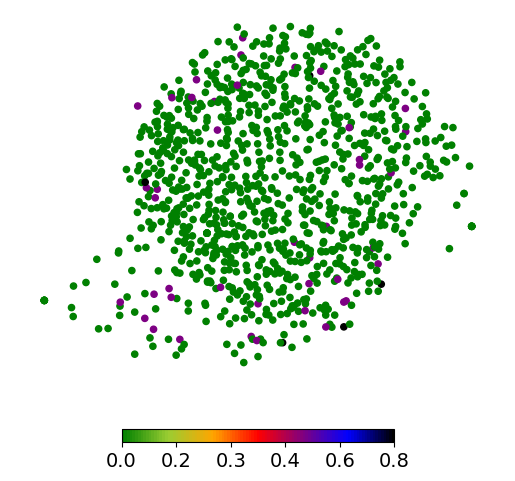

In [97]:
acc_manip.print_map_2d_colored_by_feature(feature_id='number_acc_manipulators', saveas='4_acc_manipulators_map.pdf')

**Accomplice Prevalence**

In [98]:
acc_freq = mapof.prepare_online_marriages_experiment()

In [99]:
acc_freq.add_family(culture_id = 'reverse_euclidean', size = 150, label = 'Semi-Euclidean', num_agents=4)

acc_freq.add_family(culture_id = 'norm-mallows', size = 150, label="Mallows-Identical", num_agents=4)

acc_freq.add_family(culture_id = 'asymmetric', size = 150, label = 'Mallows-MD', num_agents=4)

acc_freq.add_family(culture_id = 'symmetric', size = 150, label = 'Mallows-MA', num_agents=4)

acc_freq.add_family(culture_id = 'mallows_euclidean', size = 150, label = 'Mallows-Euclidean', num_agents=4)

acc_freq.add_family(culture_id = 'expectation', size = 150, label = 'Expectation-Euclidean', num_agents=4)

acc_freq.add_family(size = 150, label = 'Netflix', num_agents=4)

['none_4_0',
 'none_4_1',
 'none_4_2',
 'none_4_3',
 'none_4_4',
 'none_4_5',
 'none_4_6',
 'none_4_7',
 'none_4_8',
 'none_4_9',
 'none_4_10',
 'none_4_11',
 'none_4_12',
 'none_4_13',
 'none_4_14',
 'none_4_15',
 'none_4_16',
 'none_4_17',
 'none_4_18',
 'none_4_19',
 'none_4_20',
 'none_4_21',
 'none_4_22',
 'none_4_23',
 'none_4_24',
 'none_4_25',
 'none_4_26',
 'none_4_27',
 'none_4_28',
 'none_4_29',
 'none_4_30',
 'none_4_31',
 'none_4_32',
 'none_4_33',
 'none_4_34',
 'none_4_35',
 'none_4_36',
 'none_4_37',
 'none_4_38',
 'none_4_39',
 'none_4_40',
 'none_4_41',
 'none_4_42',
 'none_4_43',
 'none_4_44',
 'none_4_45',
 'none_4_46',
 'none_4_47',
 'none_4_48',
 'none_4_49',
 'none_4_50',
 'none_4_51',
 'none_4_52',
 'none_4_53',
 'none_4_54',
 'none_4_55',
 'none_4_56',
 'none_4_57',
 'none_4_58',
 'none_4_59',
 'none_4_60',
 'none_4_61',
 'none_4_62',
 'none_4_63',
 'none_4_64',
 'none_4_65',
 'none_4_66',
 'none_4_67',
 'none_4_68',
 'none_4_69',
 'none_4_70',
 'none_4_71',
 '

In [100]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0
netflix_counter = 0

for key in acc_freq.instances.keys():
    if key.startswith('reverse_euclidean'):
        acc_freq.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        acc_freq.instances[key].features['acc_freq_instance'] = rev_euclid_feature[8][reverse_euc_counter]
        reverse_euc_counter += 10
    elif key.startswith('norm-mallows_'):
        acc_freq.instances[key].votes = future_votes_mallows[mallows_counter]
        acc_freq.instances[key].features['acc_freq_instance'] = mallows_feature[8][mallows_counter]
        mallows_counter += 12
    elif key.startswith('asymmetric_'):
        acc_freq.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        acc_freq.instances[key].features['acc_freq_instance'] = mallows_MD_feature[8][mallows_MD_counter]
        mallows_MD_counter += 12
    elif key.startswith('symmetric_'):
        acc_freq.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        acc_freq.instances[key].features['acc_freq_instance'] = mallows_MA_feature[8][mallows_MA_counter]
        mallows_MA_counter += 12
    elif key.startswith('mallows_euclidean_'):
        acc_freq.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        acc_freq.instances[key].features['acc_freq_instance'] = mallows_euclidean_feature[8][mallows_euclidean_counter]
        mallows_euclidean_counter += 12
    elif key.startswith('expectation_'):
        acc_freq.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        acc_freq.instances[key].features['acc_freq_instance'] = expectations_euclidean_feature[8][expectations_euclidean_counter]
        expectations_euclidean_counter += 10
    elif key.startswith('none_'):
        acc_freq.instances[key].votes = future_votes_netflix[netflix_counter]
        acc_freq.instances[key].features['acc_freq_instance'] = netflix_feature[8][netflix_counter]
        netflix_counter += 1


In [101]:
acc_freq.features['acc_freq_instance'] = {'value':{}}
for key in acc_freq.instances.keys():
    acc_freq.features['acc_freq_instance']['value'][key] = (acc_freq.instances[key].features['acc_freq_instance'])

acc_freq.experiment_id = 'acc_freq_instance'

In [102]:
acc_freq.compute_distances(distance_id='l1-mutual_attraction')
acc_freq.embed_2d(embedding_id='kk')

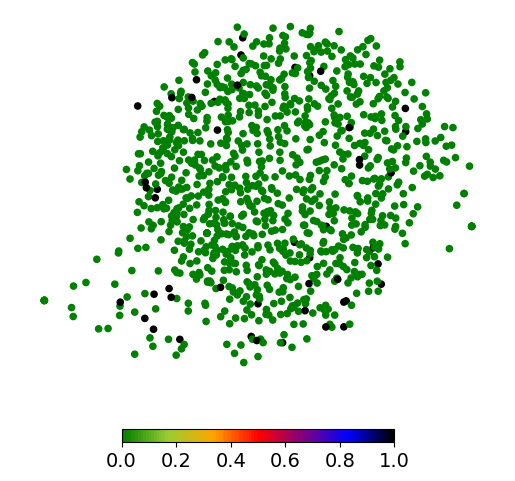

In [103]:
acc_freq.print_map_2d_colored_by_feature(feature_id='acc_freq_instance', saveas='4_acc_freq_map.pdf')

**Two for One Benefit**

In [104]:
two_benefit = mapof.prepare_online_marriages_experiment()

In [105]:
two_benefit.add_family(culture_id = 'reverse_euclidean', size = 150, label = 'Semi-Euclidean', num_agents=4)

two_benefit.add_family(culture_id = 'norm-mallows', size = 150, label="Mallows-Identical", num_agents=4)

two_benefit.add_family(culture_id = 'asymmetric', size = 150, label = 'Mallows-MD', num_agents=4)

two_benefit.add_family(culture_id = 'symmetric', size = 150, label = 'Mallows-MA', num_agents=4)

two_benefit.add_family(culture_id = 'mallows_euclidean', size = 150, label = 'Mallows-Euclidean', num_agents=4)

two_benefit.add_family(culture_id = 'expectation', size = 150, label = 'Expectation-Euclidean', num_agents=4)

two_benefit.add_family(size = 150, label = 'Netflix', num_agents=4)

['none_4_0',
 'none_4_1',
 'none_4_2',
 'none_4_3',
 'none_4_4',
 'none_4_5',
 'none_4_6',
 'none_4_7',
 'none_4_8',
 'none_4_9',
 'none_4_10',
 'none_4_11',
 'none_4_12',
 'none_4_13',
 'none_4_14',
 'none_4_15',
 'none_4_16',
 'none_4_17',
 'none_4_18',
 'none_4_19',
 'none_4_20',
 'none_4_21',
 'none_4_22',
 'none_4_23',
 'none_4_24',
 'none_4_25',
 'none_4_26',
 'none_4_27',
 'none_4_28',
 'none_4_29',
 'none_4_30',
 'none_4_31',
 'none_4_32',
 'none_4_33',
 'none_4_34',
 'none_4_35',
 'none_4_36',
 'none_4_37',
 'none_4_38',
 'none_4_39',
 'none_4_40',
 'none_4_41',
 'none_4_42',
 'none_4_43',
 'none_4_44',
 'none_4_45',
 'none_4_46',
 'none_4_47',
 'none_4_48',
 'none_4_49',
 'none_4_50',
 'none_4_51',
 'none_4_52',
 'none_4_53',
 'none_4_54',
 'none_4_55',
 'none_4_56',
 'none_4_57',
 'none_4_58',
 'none_4_59',
 'none_4_60',
 'none_4_61',
 'none_4_62',
 'none_4_63',
 'none_4_64',
 'none_4_65',
 'none_4_66',
 'none_4_67',
 'none_4_68',
 'none_4_69',
 'none_4_70',
 'none_4_71',
 '

In [106]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0
netflix_counter = 0

for key in two_benefit.instances.keys():
    if key.startswith('reverse_euclidean'):
        two_benefit.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        two_benefit.instances[key].features['avg_best_benefit_two'] = rev_euclid_feature[9][reverse_euc_counter]
        reverse_euc_counter += 10
    elif key.startswith('norm-mallows_'):
        two_benefit.instances[key].votes = future_votes_mallows[mallows_counter]
        two_benefit.instances[key].features['avg_best_benefit_two'] = mallows_feature[9][mallows_counter]
        mallows_counter += 12
    elif key.startswith('asymmetric_'):
        two_benefit.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        two_benefit.instances[key].features['avg_best_benefit_two'] = mallows_MD_feature[9][mallows_MD_counter]
        mallows_MD_counter += 12
    elif key.startswith('symmetric_'):
        two_benefit.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        two_benefit.instances[key].features['avg_best_benefit_two'] = mallows_MA_feature[9][mallows_MA_counter]
        mallows_MA_counter += 12
    elif key.startswith('mallows_euclidean_'):
        two_benefit.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        two_benefit.instances[key].features['avg_best_benefit_two'] = mallows_euclidean_feature[9][mallows_euclidean_counter]
        mallows_euclidean_counter += 12
    elif key.startswith('expectation_'):
        two_benefit.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        two_benefit.instances[key].features['avg_best_benefit_two'] = expectations_euclidean_feature[9][expectations_euclidean_counter]
        expectations_euclidean_counter += 10
    elif key.startswith('none_'):
        two_benefit.instances[key].votes = future_votes_netflix[netflix_counter]
        two_benefit.instances[key].features['avg_best_benefit_two'] = netflix_feature[9][netflix_counter]
        netflix_counter += 1


In [107]:
two_benefit.features['avg_best_benefit_two'] = {'value':{}}
for key in two_benefit.instances.keys():
    two_benefit.features['avg_best_benefit_two']['value'][key] = (two_benefit.instances[key].features['avg_best_benefit_two'])

two_benefit.experiment_id = 'avg_best_benefit_two'

In [108]:
two_benefit.compute_distances(distance_id='l1-mutual_attraction')
two_benefit.embed_2d(embedding_id='kk')

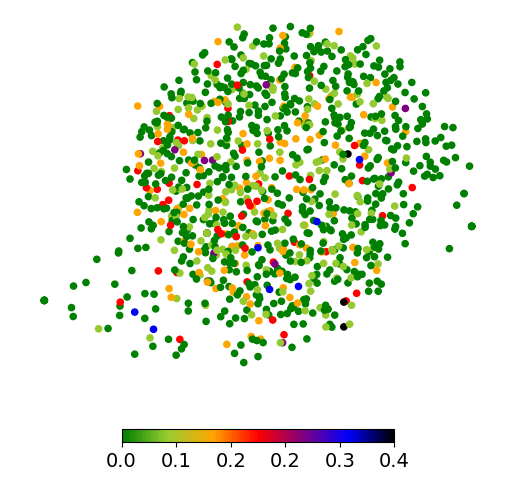

In [109]:
two_benefit.print_map_2d_colored_by_feature(feature_id='avg_best_benefit_two', saveas='4_benefit_two_map.pdf')

**Two for One Manipulability**

In [110]:
two_manip = mapof.prepare_online_marriages_experiment()

In [111]:
two_manip.add_family(culture_id = 'reverse_euclidean', size = 150, label = 'Semi-Euclidean', num_agents=4)

two_manip.add_family(culture_id = 'norm-mallows', size = 150, label="Mallows-Identical", num_agents=4)

two_manip.add_family(culture_id = 'asymmetric', size = 150, label = 'Mallows-MD', num_agents=4)

two_manip.add_family(culture_id = 'symmetric', size = 150, label = 'Mallows-MA', num_agents=4)

two_manip.add_family(culture_id = 'mallows_euclidean', size = 150, label = 'Mallows-Euclidean', num_agents=4)

two_manip.add_family(culture_id = 'expectation', size = 150, label = 'Expectation-Euclidean', num_agents=4)

two_manip.add_family(size = 150, label = 'Netflix', num_agents=4)

['none_4_0',
 'none_4_1',
 'none_4_2',
 'none_4_3',
 'none_4_4',
 'none_4_5',
 'none_4_6',
 'none_4_7',
 'none_4_8',
 'none_4_9',
 'none_4_10',
 'none_4_11',
 'none_4_12',
 'none_4_13',
 'none_4_14',
 'none_4_15',
 'none_4_16',
 'none_4_17',
 'none_4_18',
 'none_4_19',
 'none_4_20',
 'none_4_21',
 'none_4_22',
 'none_4_23',
 'none_4_24',
 'none_4_25',
 'none_4_26',
 'none_4_27',
 'none_4_28',
 'none_4_29',
 'none_4_30',
 'none_4_31',
 'none_4_32',
 'none_4_33',
 'none_4_34',
 'none_4_35',
 'none_4_36',
 'none_4_37',
 'none_4_38',
 'none_4_39',
 'none_4_40',
 'none_4_41',
 'none_4_42',
 'none_4_43',
 'none_4_44',
 'none_4_45',
 'none_4_46',
 'none_4_47',
 'none_4_48',
 'none_4_49',
 'none_4_50',
 'none_4_51',
 'none_4_52',
 'none_4_53',
 'none_4_54',
 'none_4_55',
 'none_4_56',
 'none_4_57',
 'none_4_58',
 'none_4_59',
 'none_4_60',
 'none_4_61',
 'none_4_62',
 'none_4_63',
 'none_4_64',
 'none_4_65',
 'none_4_66',
 'none_4_67',
 'none_4_68',
 'none_4_69',
 'none_4_70',
 'none_4_71',
 '

In [112]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0
netflix_counter = 0

for key in two_manip.instances.keys():
    if key.startswith('reverse_euclidean'):
        two_manip.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        two_manip.instances[key].features['number_two_manipulators'] = rev_euclid_feature[10][reverse_euc_counter]
        reverse_euc_counter += 10
    elif key.startswith('norm-mallows_'):
        two_manip.instances[key].votes = future_votes_mallows[mallows_counter]
        two_manip.instances[key].features['number_two_manipulators'] = mallows_feature[10][mallows_counter]
        mallows_counter += 12
    elif key.startswith('asymmetric_'):
        two_manip.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        two_manip.instances[key].features['number_two_manipulators'] = mallows_MD_feature[10][mallows_MD_counter]
        mallows_MD_counter += 12
    elif key.startswith('symmetric_'):
        two_manip.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        two_manip.instances[key].features['number_two_manipulators'] = mallows_MA_feature[10][mallows_MA_counter]
        mallows_MA_counter += 12
    elif key.startswith('mallows_euclidean_'):
        two_manip.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        two_manip.instances[key].features['number_two_manipulators'] = mallows_euclidean_feature[10][mallows_euclidean_counter]
        mallows_euclidean_counter += 12
    elif key.startswith('expectation_'):
        two_manip.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        two_manip.instances[key].features['number_two_manipulators'] = expectations_euclidean_feature[10][expectations_euclidean_counter]
        expectations_euclidean_counter += 10
    elif key.startswith('none_'):
        two_manip.instances[key].votes = future_votes_netflix[netflix_counter]
        two_manip.instances[key].features['number_two_manipulators'] = netflix_feature[10][netflix_counter]
        netflix_counter += 1


In [113]:
two_manip.features['number_two_manipulators'] = {'value':{}}
for key in two_manip.instances.keys():
    two_manip.features['number_two_manipulators']['value'][key] = (two_manip.instances[key].features['number_two_manipulators'])

two_manip.experiment_id = 'number_two_manipulators'

In [114]:
two_manip.compute_distances(distance_id='l1-mutual_attraction')
two_manip.embed_2d(embedding_id='kk')

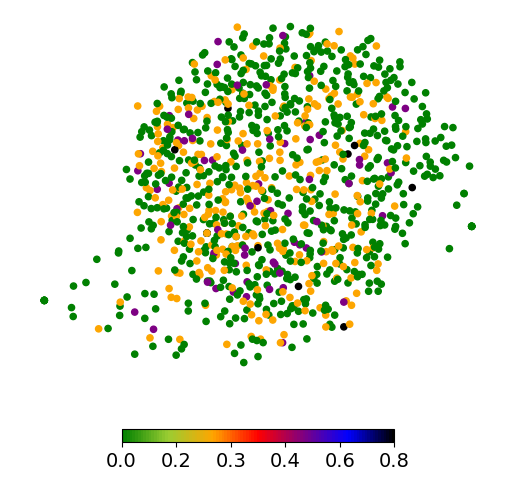

In [115]:
two_manip.print_map_2d_colored_by_feature(feature_id='number_two_manipulators', saveas='4_two_manipulators_map.pdf')

**Two for One Prevalence**

In [116]:
two_prev = mapof.prepare_online_marriages_experiment()

In [117]:
two_prev.add_family(culture_id = 'reverse_euclidean', size = 150, label = 'Semi-Euclidean', num_agents=4)

two_prev.add_family(culture_id = 'norm-mallows', size = 150, label="Mallows-Identical", num_agents=4)

two_prev.add_family(culture_id = 'asymmetric', size = 150, label = 'Mallows-MD', num_agents=4)

two_prev.add_family(culture_id = 'symmetric', size = 150, label = 'Mallows-MA', num_agents=4)

two_prev.add_family(culture_id = 'mallows_euclidean', size = 150, label = 'Mallows-Euclidean', num_agents=4)

two_prev.add_family(culture_id = 'expectation', size = 150, label = 'Expectation-Euclidean', num_agents=4)

two_prev.add_family(size = 150, label = 'Netflix', num_agents=4)

['none_4_0',
 'none_4_1',
 'none_4_2',
 'none_4_3',
 'none_4_4',
 'none_4_5',
 'none_4_6',
 'none_4_7',
 'none_4_8',
 'none_4_9',
 'none_4_10',
 'none_4_11',
 'none_4_12',
 'none_4_13',
 'none_4_14',
 'none_4_15',
 'none_4_16',
 'none_4_17',
 'none_4_18',
 'none_4_19',
 'none_4_20',
 'none_4_21',
 'none_4_22',
 'none_4_23',
 'none_4_24',
 'none_4_25',
 'none_4_26',
 'none_4_27',
 'none_4_28',
 'none_4_29',
 'none_4_30',
 'none_4_31',
 'none_4_32',
 'none_4_33',
 'none_4_34',
 'none_4_35',
 'none_4_36',
 'none_4_37',
 'none_4_38',
 'none_4_39',
 'none_4_40',
 'none_4_41',
 'none_4_42',
 'none_4_43',
 'none_4_44',
 'none_4_45',
 'none_4_46',
 'none_4_47',
 'none_4_48',
 'none_4_49',
 'none_4_50',
 'none_4_51',
 'none_4_52',
 'none_4_53',
 'none_4_54',
 'none_4_55',
 'none_4_56',
 'none_4_57',
 'none_4_58',
 'none_4_59',
 'none_4_60',
 'none_4_61',
 'none_4_62',
 'none_4_63',
 'none_4_64',
 'none_4_65',
 'none_4_66',
 'none_4_67',
 'none_4_68',
 'none_4_69',
 'none_4_70',
 'none_4_71',
 '

In [ ]:
reverse_euc_counter = 0
mallows_counter = 0
mallows_MD_counter = 0
mallows_MA_counter = 0
mallows_euclidean_counter = 0
expectations_euclidean_counter = 0
netflix_counter = 0

for key in two_prev.instances.keys():
    if key.startswith('reverse_euclidean'):
        two_prev.instances[key].votes = future_votes_rev_euclidean[reverse_euc_counter]
        two_prev.instances[key].features['two_freq_instance'] = rev_euclid_feature[11][reverse_euc_counter]
        reverse_euc_counter += 10
    elif key.startswith('norm-mallows_'):
        two_prev.instances[key].votes = future_votes_mallows[mallows_counter]
        two_prev.instances[key].features['two_freq_instance'] = mallows_feature[11][mallows_counter]
        mallows_counter += 12
    elif key.startswith('asymmetric_'):
        two_prev.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        two_prev.instances[key].features['two_freq_instance'] = mallows_MD_feature[11][mallows_MD_counter]
        mallows_MD_counter += 12
    elif key.startswith('symmetric_'):
        two_prev.instances[key].votes = future_votes_mallows_MA[mallows_MA_counter]
        two_prev.instances[key].features['two_freq_instance'] = mallows_MA_feature[11][mallows_MA_counter]
        mallows_MA_counter += 12
    elif key.startswith('mallows_euclidean_'):
        two_prev.instances[key].votes = future_votes_mallows_euclidean[mallows_euclidean_counter]
        two_prev.instances[key].features['two_freq_instance'] = mallows_euclidean_feature[11][mallows_euclidean_counter]
        mallows_euclidean_counter += 12
    elif key.startswith('expectation_'):
        two_prev.instances[key].votes = future_votes_expectations_euclidean[expectations_euclidean_counter]
        two_prev.instances[key].features['two_freq_instance'] = expectations_euclidean_feature[11][expectations_euclidean_counter]
        expectations_euclidean_counter += 10
    elif key.startswith('none_'):
        two_prev.instances[key].votes = future_votes_netflix[netflix_counter]
        two_prev.instances[key].features['number_two_manipulators'] = netflix_feature[11][netflix_counter]
        netflix_counter += 1


In [119]:
two_prev.features['two_freq_instance'] = {'value':{}}
for key in two_prev.instances.keys():
    two_prev.features['two_freq_instance']['value'][key] = (two_prev.instances[key].features['two_freq_instance'])

two_prev.experiment_id = 'two_freq_instance'

In [120]:
two_prev.compute_distances(distance_id='l1-mutual_attraction')
two_prev.embed_2d(embedding_id='kk')

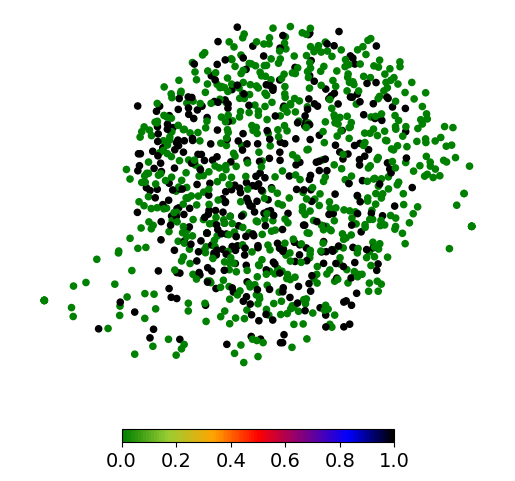

In [121]:
two_prev.print_map_2d_colored_by_feature(feature_id='two_freq_instance', saveas='4_two_freq_map.pdf')

In [197]:
mallows_MD["Both Phis"] = list(zip(mallows_MD["phi_m"], mallows_MD["phi_w"]))

In [140]:
netflix["Both Phis"] = -1

In [ ]:
import pandas as pd
from itertools import product

# Generate all possible tuple combinations of {0.0, 0.2, 0.4, 0.6, 0.8, 1.0}
phi_values = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

# Create a mapping from each unique tuple to an integer indicator
unique_tuples = list(product(phi_values, repeat=2))  # 36 combinations
tuple_to_indicator = {tup: idx for idx, tup in enumerate(unique_tuples)}

# Apply to your DataFrame
mallows_MD["Both Phis"] = mallows_MD["Both Phis"].map(tuple_to_indicator)

In [209]:
netflix_feature = [netflix['trunc_count'], netflix['trunc_egal'], netflix['trunc_prevalence'],
                    netflix['num_self_manipulators'], netflix['avg_self_benefit'], 
                      netflix['self_freq_instance'], netflix['avg_best_benefit_acc'], netflix['number_acc_manipulators'],
                      netflix['acc_freq_instance'], netflix['avg_best_benefit_two'], netflix['number_two_manipulators'],
                      netflix['two_freq_instance'], netflix['Both Phis']]
mallows_MD_feature = [mallows_MD['trunc_count'], mallows_MD['trunc_egal'], mallows_MD['trunc_prevalence'],
                    mallows_MD['num_self_manipulators'], mallows_MD['avg_self_benefit'], 
                      mallows_MD['self_freq_instance'], mallows_MD['avg_best_benefit_acc'], mallows_MD['number_acc_manipulators'],
                      mallows_MD['acc_freq_instance'], mallows_MD['avg_best_benefit_two'], mallows_MD['number_two_manipulators'],
                      mallows_MD['two_freq_instance'], mallows_MD['Both Phis']]

In [142]:
both_phi = mapof.prepare_online_marriages_experiment()

In [143]:
both_phi.add_family(size = 150, label = 'Netflix', num_agents=4)
both_phi.add_family(culture_id = 'asymmetric', size = 150, label = 'Mallows-MD', num_agents=4)

['asymmetric_4_0',
 'asymmetric_4_1',
 'asymmetric_4_2',
 'asymmetric_4_3',
 'asymmetric_4_4',
 'asymmetric_4_5',
 'asymmetric_4_6',
 'asymmetric_4_7',
 'asymmetric_4_8',
 'asymmetric_4_9',
 'asymmetric_4_10',
 'asymmetric_4_11',
 'asymmetric_4_12',
 'asymmetric_4_13',
 'asymmetric_4_14',
 'asymmetric_4_15',
 'asymmetric_4_16',
 'asymmetric_4_17',
 'asymmetric_4_18',
 'asymmetric_4_19',
 'asymmetric_4_20',
 'asymmetric_4_21',
 'asymmetric_4_22',
 'asymmetric_4_23',
 'asymmetric_4_24',
 'asymmetric_4_25',
 'asymmetric_4_26',
 'asymmetric_4_27',
 'asymmetric_4_28',
 'asymmetric_4_29',
 'asymmetric_4_30',
 'asymmetric_4_31',
 'asymmetric_4_32',
 'asymmetric_4_33',
 'asymmetric_4_34',
 'asymmetric_4_35',
 'asymmetric_4_36',
 'asymmetric_4_37',
 'asymmetric_4_38',
 'asymmetric_4_39',
 'asymmetric_4_40',
 'asymmetric_4_41',
 'asymmetric_4_42',
 'asymmetric_4_43',
 'asymmetric_4_44',
 'asymmetric_4_45',
 'asymmetric_4_46',
 'asymmetric_4_47',
 'asymmetric_4_48',
 'asymmetric_4_49',
 'asymmetr

In [158]:
mallows_MD_counter = 0
netflix_counter = 0

mallows_indices = []


for key in both_phi.instances.keys():
    if key.startswith('asymmetric_'):
        both_phi.instances[key].votes = future_votes_mallows_MD[mallows_MD_counter]
        both_phi.instances[key].features['Both_Phi'] = mallows_MD_feature[12][mallows_MD_counter]
        mallows_indices.append(mallows_MD_counter)
        mallows_MD_counter += 12
    elif key.startswith('none_'):
        both_phi.instances[key].votes = future_votes_netflix[netflix_counter]
        both_phi.instances[key].features['Both_Phi'] = netflix_feature[12][netflix_counter]
        netflix_counter += 1


In [145]:
both_phi.features['Both_Phi'] = {'value':{}}
for key in both_phi.instances.keys():
    both_phi.features['Both_Phi']['value'][key] = (both_phi.instances[key].features['Both_Phi'])

both_phi.experiment_id = 'Both_Phi'

In [146]:
both_phi.compute_distances(distance_id='l1-mutual_attraction')
both_phi.embed_2d(embedding_id='kk')

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/optimization_algorithms.py:56: RuntimeWarning: invalid value encountered in divide
  step_size = np.linalg.norm(s, axis=0) ** 2 / denominator


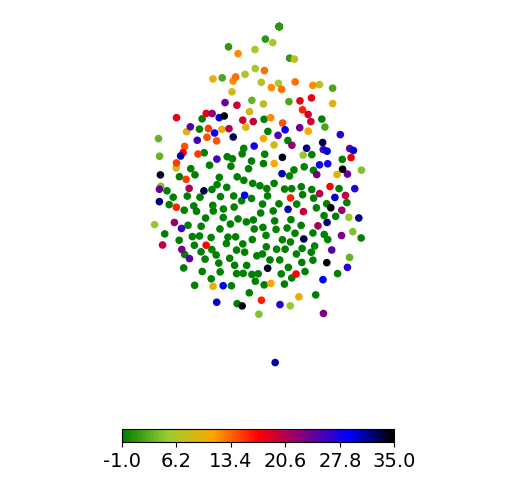

In [147]:
both_phi.print_map_2d_colored_by_feature(feature_id='Both_Phi')

In [159]:
no_0 = mallows_MD.loc[mallows_indices]

In [164]:
no_0 = no_0[(no_0['phi_m'] != 0.0) & (no_0['phi_w'] != 0.0)]

In [167]:
indices = no_0.index.tolist()

In [169]:
netflix_feature = [netflix['trunc_count'], netflix['trunc_egal'], netflix['trunc_prevalence'],
                    netflix['num_self_manipulators'], netflix['avg_self_benefit'], 
                      netflix['self_freq_instance'], netflix['avg_best_benefit_acc'], netflix['number_acc_manipulators'],
                      netflix['acc_freq_instance'], netflix['avg_best_benefit_two'], netflix['number_two_manipulators'],
                      netflix['two_freq_instance'], netflix['Both Phis']]
mallows_MD_feature = [mallows_MD['trunc_count'], mallows_MD['trunc_egal'], mallows_MD['trunc_prevalence'],
                    mallows_MD['num_self_manipulators'], mallows_MD['avg_self_benefit'], 
                      mallows_MD['self_freq_instance'], mallows_MD['avg_best_benefit_acc'], mallows_MD['number_acc_manipulators'],
                      mallows_MD['acc_freq_instance'], mallows_MD['avg_best_benefit_two'], mallows_MD['number_two_manipulators'],
                      mallows_MD['two_freq_instance'], mallows_MD['Both Phis']]

In [170]:
no_zero = mapof.prepare_online_marriages_experiment()

In [171]:
no_zero.add_family(size = 150, label = 'Netflix', num_agents=4)
no_zero.add_family(culture_id = 'asymmetric', size = 100, label = 'Mallows-MD', num_agents=4)

['asymmetric_4_0',
 'asymmetric_4_1',
 'asymmetric_4_2',
 'asymmetric_4_3',
 'asymmetric_4_4',
 'asymmetric_4_5',
 'asymmetric_4_6',
 'asymmetric_4_7',
 'asymmetric_4_8',
 'asymmetric_4_9',
 'asymmetric_4_10',
 'asymmetric_4_11',
 'asymmetric_4_12',
 'asymmetric_4_13',
 'asymmetric_4_14',
 'asymmetric_4_15',
 'asymmetric_4_16',
 'asymmetric_4_17',
 'asymmetric_4_18',
 'asymmetric_4_19',
 'asymmetric_4_20',
 'asymmetric_4_21',
 'asymmetric_4_22',
 'asymmetric_4_23',
 'asymmetric_4_24',
 'asymmetric_4_25',
 'asymmetric_4_26',
 'asymmetric_4_27',
 'asymmetric_4_28',
 'asymmetric_4_29',
 'asymmetric_4_30',
 'asymmetric_4_31',
 'asymmetric_4_32',
 'asymmetric_4_33',
 'asymmetric_4_34',
 'asymmetric_4_35',
 'asymmetric_4_36',
 'asymmetric_4_37',
 'asymmetric_4_38',
 'asymmetric_4_39',
 'asymmetric_4_40',
 'asymmetric_4_41',
 'asymmetric_4_42',
 'asymmetric_4_43',
 'asymmetric_4_44',
 'asymmetric_4_45',
 'asymmetric_4_46',
 'asymmetric_4_47',
 'asymmetric_4_48',
 'asymmetric_4_49',
 'asymmetr

In [175]:
mallows_MD_counter = 0
netflix_counter = 0


for key in no_zero.instances.keys():
    if key.startswith('asymmetric_'):
        no_zero.instances[key].votes = future_votes_mallows_MD[indices[mallows_MD_counter]]
        no_zero.instances[key].features['Both_Phi'] = mallows_MD_feature[12][indices[mallows_MD_counter]]
        mallows_indices.append(mallows_MD_counter)
        mallows_MD_counter += 1
    elif key.startswith('none_'):
        no_zero.instances[key].votes = future_votes_netflix[netflix_counter]
        no_zero.instances[key].features['Both_Phi'] = netflix_feature[12][netflix_counter]
        netflix_counter += 1

In [177]:
no_zero.features['Both_Phi'] = {'value':{}}
for key in no_zero.instances.keys():
    no_zero.features['Both_Phi']['value'][key] = (no_zero.instances[key].features['Both_Phi'])

no_zero.experiment_id = 'Both_Phi'

In [178]:
no_zero.compute_distances(distance_id='l1-mutual_attraction')
no_zero.embed_2d(embedding_id='kk')

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/optimization_algorithms.py:56: RuntimeWarning: divide by zero encountered in divide
  step_size = np.linalg.norm(s, axis=0) ** 2 / denominator
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/optimization_algorithms.py:62: RuntimeWarning: invalid value encountered in multiply
  x = x - step_size * g
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/energy_functions.py:5: RuntimeWarning: invalid value encountered in subtract
  positions_delta = positions[:, np.newaxis, :] - positions[np.newaxis, :, :]
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/energy_functions.py:9: RuntimeWarning: invalid value encountered in subtract
  my_matrix = k * (pos_squared + l ** 2 - 2 * l * np.sqrt(po

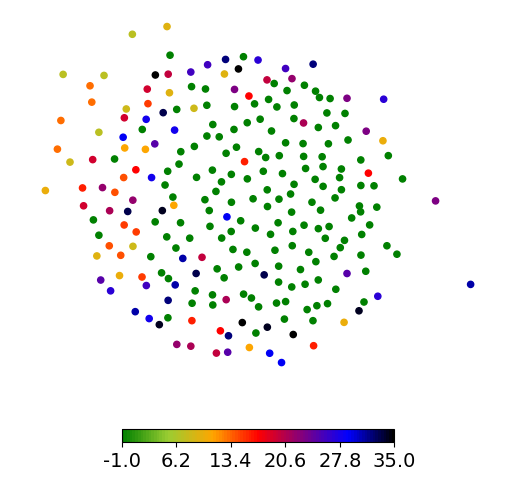

In [179]:
no_zero.print_map_2d_colored_by_feature(feature_id='Both_Phi')

In [185]:
print(tuple_to_indicator)

{(0.0, 0.0): 0, (0.0, 0.2): 1, (0.0, 0.4): 2, (0.0, 0.6): 3, (0.0, 0.8): 4, (0.0, 1.0): 5, (0.2, 0.0): 6, (0.2, 0.2): 7, (0.2, 0.4): 8, (0.2, 0.6): 9, (0.2, 0.8): 10, (0.2, 1.0): 11, (0.4, 0.0): 12, (0.4, 0.2): 13, (0.4, 0.4): 14, (0.4, 0.6): 15, (0.4, 0.8): 16, (0.4, 1.0): 17, (0.6, 0.0): 18, (0.6, 0.2): 19, (0.6, 0.4): 20, (0.6, 0.6): 21, (0.6, 0.8): 22, (0.6, 1.0): 100, (0.8, 0.0): 24, (0.8, 0.2): 25, (0.8, 0.4): 26, (0.8, 0.6): 27, (0.8, 0.8): 28, (0.8, 1.0): 29, (1.0, 0.0): 30, (1.0, 0.2): 31, (1.0, 0.4): 32, (1.0, 0.6): 100, (1.0, 0.8): 34, (1.0, 1.0): 35}


In [192]:
tuple_to_indicator[(1.0, 0.6)] = 100
tuple_to_indicator[(0.6, 1.0)] = 100

In [198]:
mallows_MD["Both Phis"] = mallows_MD["Both Phis"].map(tuple_to_indicator)

In [199]:
no_0 = mallows_MD.loc[mallows_indices]
no_0 = no_0[(no_0['phi_m'] != 0.0) & (no_0['phi_w'] != 0.0)]

In [210]:
special_phi = mapof.prepare_online_marriages_experiment()
special_phi.add_family(size = 150, label = 'Netflix', num_agents=4)
special_phi.add_family(culture_id = 'asymmetric', size = 100, label = 'Mallows-MD', num_agents=4)

['asymmetric_4_0',
 'asymmetric_4_1',
 'asymmetric_4_2',
 'asymmetric_4_3',
 'asymmetric_4_4',
 'asymmetric_4_5',
 'asymmetric_4_6',
 'asymmetric_4_7',
 'asymmetric_4_8',
 'asymmetric_4_9',
 'asymmetric_4_10',
 'asymmetric_4_11',
 'asymmetric_4_12',
 'asymmetric_4_13',
 'asymmetric_4_14',
 'asymmetric_4_15',
 'asymmetric_4_16',
 'asymmetric_4_17',
 'asymmetric_4_18',
 'asymmetric_4_19',
 'asymmetric_4_20',
 'asymmetric_4_21',
 'asymmetric_4_22',
 'asymmetric_4_23',
 'asymmetric_4_24',
 'asymmetric_4_25',
 'asymmetric_4_26',
 'asymmetric_4_27',
 'asymmetric_4_28',
 'asymmetric_4_29',
 'asymmetric_4_30',
 'asymmetric_4_31',
 'asymmetric_4_32',
 'asymmetric_4_33',
 'asymmetric_4_34',
 'asymmetric_4_35',
 'asymmetric_4_36',
 'asymmetric_4_37',
 'asymmetric_4_38',
 'asymmetric_4_39',
 'asymmetric_4_40',
 'asymmetric_4_41',
 'asymmetric_4_42',
 'asymmetric_4_43',
 'asymmetric_4_44',
 'asymmetric_4_45',
 'asymmetric_4_46',
 'asymmetric_4_47',
 'asymmetric_4_48',
 'asymmetric_4_49',
 'asymmetr

In [211]:
mallows_MD_counter = 0
netflix_counter = 0


for key in special_phi.instances.keys():
    if key.startswith('asymmetric_'):
        special_phi.instances[key].votes = future_votes_mallows_MD[indices[mallows_MD_counter]]
        special_phi.instances[key].features['Both_Phi'] = mallows_MD_feature[12][indices[mallows_MD_counter]]
        mallows_MD_counter += 1
    elif key.startswith('none_'):
        special_phi.instances[key].votes = future_votes_netflix[netflix_counter]
        special_phi.instances[key].features['Both_Phi'] = netflix_feature[12][netflix_counter]
        netflix_counter += 1

In [212]:
special_phi.features['Both_Phi'] = {'value':{}}
for key in special_phi.instances.keys():
    special_phi.features['Both_Phi']['value'][key] = (special_phi.instances[key].features['Both_Phi'])

special_phi.experiment_id = 'Both_Phi'

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/optimization_algorithms.py:56: RuntimeWarning: divide by zero encountered in divide
  step_size = np.linalg.norm(s, axis=0) ** 2 / denominator
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/optimization_algorithms.py:62: RuntimeWarning: invalid value encountered in multiply
  x = x - step_size * g
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/energy_functions.py:5: RuntimeWarning: invalid value encountered in subtract
  positions_delta = positions[:, np.newaxis, :] - positions[np.newaxis, :, :]
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/mapof/core/embedding/kamada_kawai/energy_functions.py:9: RuntimeWarning: invalid value encountered in subtract
  my_matrix = k * (pos_squared + l ** 2 - 2 * l * np.sqrt(po

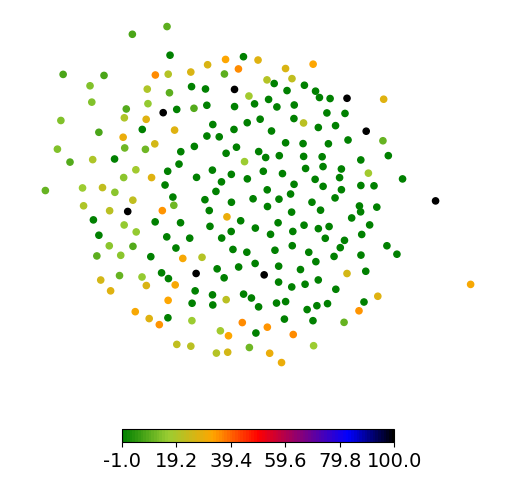

In [214]:
special_phi.compute_distances(distance_id='l1-mutual_attraction')
special_phi.embed_2d(embedding_id='kk')
special_phi.print_map_2d_colored_by_feature(feature_id='Both_Phi')